### 組員分工與資料來源
|組員|分工|
|----|----|
|蔡睿|判斷主題可行度、撰寫程式|
|盧俋翔|製作簡報、撰寫程式|
|劉羿頡|製作簡報、尋找資料|
|許竣傑|主題發想、尋找資料|

資料來源:FastF1(https://docs.fastf1.dev/)、(https://github.com/theOehrly/Fast-F1 
)

資料下載／取得日期：2026 年 10 月 14 日。

In [2]:
%pip install -q pandas numpy matplotlib seaborn statsmodels


[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 設定 Seaborn 預設主題，讓整份報告的圖表風格統一
sns.set_theme(style="whitegrid")

# 資料理解與清理

本專案使用兩份資料：
- `f1_2023_8races_raw.csv`：原始資料（8,649 筆），保留每一圈的 `PitInTime` / `PitOutTime`，用於計算進站時間損失（圖表四）。
- `f1_2023_8races_clean.csv`：已清理資料（7,497 筆），用於輪胎衰退與圈速分析（圖表一、二、三、五）。

## 1.1 型別轉換：進出站時間
原始資料中的 `PitInTime`、`PitOutTime` 是字串格式，無法直接相減。我們用 `pd.to_timedelta` 轉成時間格式，並設定 `errors='coerce'`：沒有進出站的圈（欄位為空）會轉成 `NaT`，不會讓程式出錯。

## 1.2 刪除 C5 輪胎
C5 是 Pirelli 最軟的配方，在這 8 場正賽中只有 **2 圈**使用紀錄，樣本太少，無法估計衰退趨勢，也會干擾繪圖與期末模型，因此從資料中剔除（7,497 → 7,495 筆）。

## 1.3 賽道標準化、燃油校正與極端慢圈過濾
直接比較原始單圈時間（圖表一原版）會受到非輪胎因素干擾，因此做了三項處理：
1. **賽道標準化**：每條賽道長度不同，原始圈速無法互相比較。改用 `LapTime_Delta` = 單圈時間 − 該場比賽最快單圈，消除賽道長度差異。
2. **燃油校正**：隨著燃油消耗、車重下降，車子會越跑越快，這會掩蓋輪胎衰退。我們假設每圈因燃油減少快 0.06 秒，並把這段時間加回去：`Fuel_Corrected_Delta` = `LapTime_Delta` + 圈數 × 0.06。
3. **過濾極端慢圈**：只保留 `Fuel_Corrected_Delta` < 10 秒的圈，排除失誤、被套圈等造成的極端慢圈，避免趨勢線被拉偏，共排除 **7 圈**。此過濾用在圖表一修正版與圖表二；圖表五沒有刪除資料，只用 Y 軸範圍（1.5–10 秒）限制顯示。

## 1.4 過濾過短的 stint
分析輪胎壽命（圖表三）時，以「場次 × 車手 × stint」為單位，取每套輪胎的最大使用圈數 (`TyreLife`)。跑不到 5 圈的 stint 通常是爆胎、碰撞退賽，或最後幾圈換胎刷最速圈造成的，不能代表輪胎真正的壽命，因此只保留 **≥ 5 圈**的 stint（424 → 417 個）。

## 1.5 進站時間計算與異常值過濾
FastF1 把 `PitInTime` 記錄在進站圈 (In-Lap)，`PitOutTime` 記錄在下一圈的出站圈 (Out-Lap)。我們針對同一位車手，把下一圈的 `PitOutTime` 往上對齊，再減去這一圈的 `PitInTime`，得到通過維修區的實際時間 `Pit_Duration_Seconds`。
正常進站通過維修區約 20–35 秒，所以只保留 **15–40 秒**的紀錄，排除起跑前、紅旗停頓或其他異常的極端值（309 → 297 筆）。


In [5]:
# ==========================================
# 由原始資料產生乾淨資料 (raw → clean)
# ==========================================
df_raw = pd.read_csv("f1_2023_8races_raw.csv")
print("原始資料維度：", df_raw.shape)
print("(場次, 車手, 圈數) 重複筆數：", df_raw.duplicated(["RoundNumber", "Driver", "LapNumber"]).sum())
print("LapTime 缺失筆數：", df_raw["LapTime_seconds"].isna().sum())

# 逐步過濾，記錄每一步刪除的筆數
steps = [
    ("① 刪除 LapTime 缺失",                  df_raw["LapTime_seconds"].notna()),
    ("② 刪除進站圈與出站圈",                  df_raw["PitInTime"].isna() & df_raw["PitOutTime"].isna()),
    ("③ 只保留綠旗圈 (TrackStatus == 1)",     df_raw["TrackStatus"].astype(str) == "1"),
    ("④ 只保留計時準確的圈 (IsAccurate)",      df_raw["IsAccurate"]),
]
keep = pd.Series(True, index=df_raw.index)
for name, cond in steps:
    before = keep.sum()
    keep &= cond
    print(f"{name}：刪除 {before - keep.sum()} 筆，剩 {keep.sum()} 筆")

# 新增特徵：相對軟硬 → Pirelli 實際配方；賽道嚴苛度
compound_alloc = {
    1:  {"HARD": "C1", "MEDIUM": "C2", "SOFT": "C3"},  # 巴林
    4:  {"HARD": "C3", "MEDIUM": "C4", "SOFT": "C5"},  # 亞塞拜然
    7:  {"HARD": "C1", "MEDIUM": "C2", "SOFT": "C3"},  # 西班牙
    9:  {"HARD": "C3", "MEDIUM": "C4", "SOFT": "C5"},  # 奧地利
    10: {"HARD": "C1", "MEDIUM": "C2", "SOFT": "C3"},  # 英國
    14: {"HARD": "C3", "MEDIUM": "C4", "SOFT": "C5"},  # 義大利
    16: {"HARD": "C1", "MEDIUM": "C2", "SOFT": "C3"},  # 日本
    22: {"HARD": "C3", "MEDIUM": "C4", "SOFT": "C5"},  # 阿布達比
}
track_severity = {1: 5, 4: 2, 7: 5, 9: 3, 10: 5, 14: 2, 16: 5, 22: 3}

df_clean = df_raw.loc[keep].copy()
df_clean["True_Compound"] = df_clean.apply(
    lambda r: compound_alloc[r["RoundNumber"]][r["Compound"]], axis=1)
df_clean["Track_Severity"] = df_clean["RoundNumber"].map(track_severity)

df_clean.to_csv("f1_2023_8races_clean.csv", index=False)
print("\n已輸出乾淨資料：", df_clean.shape)


原始資料維度： (8649, 17)
(場次, 車手, 圈數) 重複筆數： 0
LapTime 缺失筆數： 110
① 刪除 LapTime 缺失：刪除 110 筆，剩 8539 筆
② 刪除進站圈與出站圈：刪除 598 筆，剩 7941 筆
③ 只保留綠旗圈 (TrackStatus == 1)：刪除 368 筆，剩 7573 筆
④ 只保留計時準確的圈 (IsAccurate)：刪除 76 筆，剩 7497 筆

已輸出乾淨資料： (7497, 19)


### 圖表一：輪胎衰退曲線與趨勢 (Degradation Trendlines)

**【圖表目的】**
驗證「越軟的配方衰退越快」的賽車物理常識，並從中萃取不同配方的「每圈時間衰退斜率」。

**【實作方法】**
使用 Seaborn 的 `lmplot` 繪製輪胎壽命 (TyreLife) 與單圈秒數 (LapTime) 的散佈圖，並透過線性迴歸 (Linear Regression) 擬合出 C1 至 C4 的趨勢線。為了避免上千筆資料點互相遮蔽，將散佈點透明度降低，凸顯迴歸線的斜率差異。這幾條迴歸線的斜率，將作為期末 Gurobi 最佳化模型中的關鍵時間成本參數。

/Users/raytsai/Desktop/DADM2026/.venv/lib/python3.12/site-packages/numpy/linalg/_linalg.py:3437: RuntimeWarning: divide by zero encountered in matmul
  return _core_matmul(x1, x2)
/Users/raytsai/Desktop/DADM2026/.venv/lib/python3.12/site-packages/numpy/linalg/_linalg.py:3437: RuntimeWarning: overflow encountered in matmul
  return _core_matmul(x1, x2)
/Users/raytsai/Desktop/DADM2026/.venv/lib/python3.12/site-packages/numpy/linalg/_linalg.py:3437: RuntimeWarning: invalid value encountered in matmul
  return _core_matmul(x1, x2)


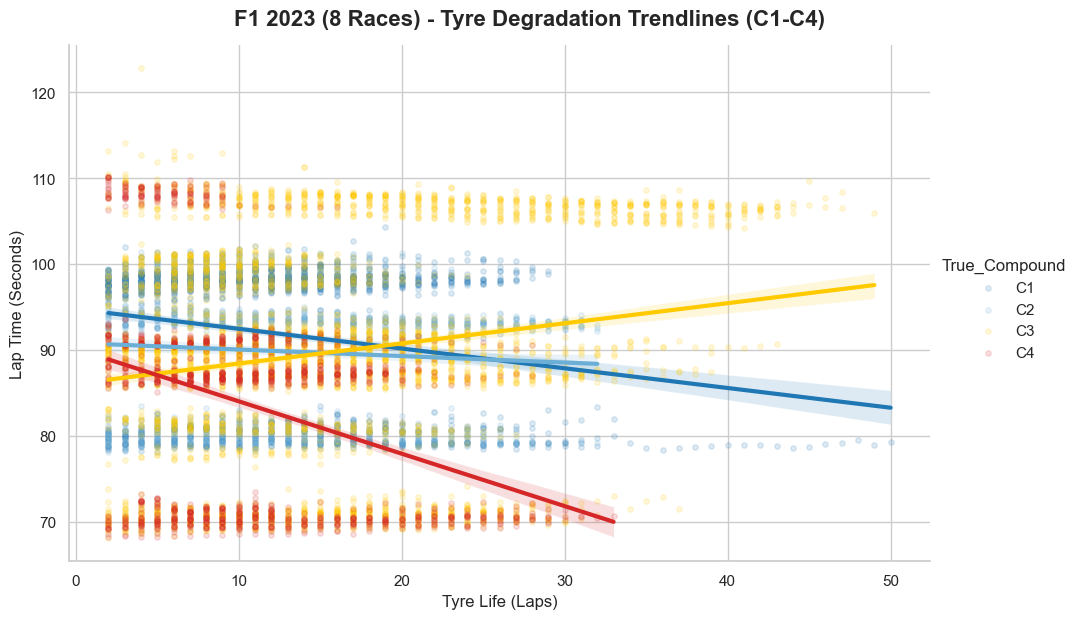

In [7]:
# 為了讓圖表更易讀，我們定義 C1 到 C4 的顯示順序與專屬顏色
# C1(最硬)用深藍，C2淺藍，C3黃色(對應官方常駐中性胎印象)，C4紅色(最軟)
compound_order = ['C1', 'C2', 'C3', 'C4']
compound_colors = {'C1': '#1f77b4', 'C2': '#6baed6', 'C3': '#ffca00', 'C4': '#d62728'}

# 使用 Seaborn 的 lmplot (Linear Model Plot) 同時畫出散佈圖與迴歸趨勢線
g = sns.lmplot(
    data=df_clean,
    x="TyreLife",             # X軸：輪胎使用了幾圈
    y="LapTime_seconds",      # Y軸：單圈秒數
    hue="True_Compound",      # 用 C1~C4 來分類畫線
    hue_order=compound_order,
    palette=compound_colors,
    scatter_kws={'alpha': 0.15, 's': 15}, # 透明度調低至 15%，點大小縮小，凸顯趨勢線
    line_kws={'linewidth': 3},            # 迴歸線加粗
    height=6,                 # 圖表高度
    aspect=1.6                # 圖表長寬比
)

# 調整標題與座標軸標籤
g.fig.suptitle("F1 2023 (8 Races) - Tyre Degradation Trendlines (C1-C4)", y=1.03, fontsize=16, fontweight='bold')
g.set_axis_labels("Tyre Life (Laps)", "Lap Time (Seconds)", fontsize=12)

# 顯示圖表
plt.show()

## 在上圖可以看到c1,c2,c4胎看起來不太符合我們預期的胎越軟速度越快、lap time應隨tyre life增加而變長等 我們對程式做出以下優化：
### 1.將賽道標準化(lap time-該場最速成績)
### 2.假設燃油每圈會讓賽車快0.06秒 在這邊我們把它加回去
### 3.消除過慢的圈速成績

/Users/raytsai/Desktop/DADM2026/.venv/lib/python3.12/site-packages/numpy/linalg/_linalg.py:3437: RuntimeWarning: divide by zero encountered in matmul
  return _core_matmul(x1, x2)
/Users/raytsai/Desktop/DADM2026/.venv/lib/python3.12/site-packages/numpy/linalg/_linalg.py:3437: RuntimeWarning: overflow encountered in matmul
  return _core_matmul(x1, x2)
/Users/raytsai/Desktop/DADM2026/.venv/lib/python3.12/site-packages/numpy/linalg/_linalg.py:3437: RuntimeWarning: invalid value encountered in matmul
  return _core_matmul(x1, x2)


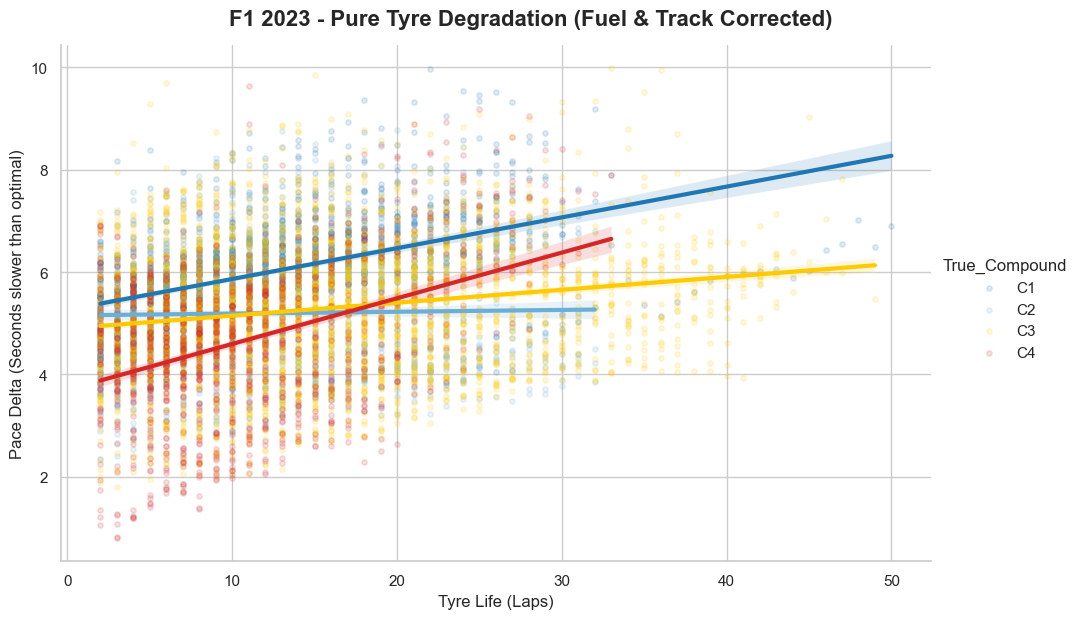

In [8]:
df = pd.read_csv("f1_2023_8races_clean.csv")

# 1. 計算每場比賽的最快單圈作為基準
df['Fastest_Lap'] = df.groupby('RoundNumber')['LapTime_seconds'].transform('min')

# 2. 計算 LapTime Delta (比該場最快單圈慢幾秒)，消除賽道長度差異
df['LapTime_Delta'] = df['LapTime_seconds'] - df['Fastest_Lap']

# 3. 燃油校正 (Fuel Correction)
# 假設每圈消耗燃油會讓車子變快 0.06 秒，我們把這個時間「加回去」，消除油載干擾
df['Fuel_Corrected_Delta'] = df['LapTime_Delta'] + (df['LapNumber'] * 0.06)

# 為了讓趨勢線不受極端慢車(例如失誤或被套圈)干擾，我們只保留 Delta 在 10 秒內的正常圈速
df_plot = df[df['Fuel_Corrected_Delta'] < 10].copy()

# ==========================================
# 開始繪製升級版圖表
# ==========================================
sns.set_theme(style="whitegrid", palette="muted")
compound_order = ['C1', 'C2', 'C3', 'C4']
compound_colors = {'C1': '#1f77b4', 'C2': '#6baed6', 'C3': '#ffca00', 'C4': '#d62728'}

g = sns.lmplot(
    data=df_plot,
    x="TyreLife",             
    y="Fuel_Corrected_Delta", # 改用校正後的 Delta 秒數
    hue="True_Compound",      
    hue_order=compound_order,
    palette=compound_colors,
    scatter_kws={'alpha': 0.15, 's': 15}, 
    line_kws={'linewidth': 3},            
    height=6,                 
    aspect=1.6                
)

g.fig.suptitle("F1 2023 - Pure Tyre Degradation (Fuel & Track Corrected)", y=1.03, fontsize=16, fontweight='bold')
g.set_axis_labels("Tyre Life (Laps)", "Pace Delta (Seconds slower than optimal)", fontsize=12)

plt.show()

--------------------

### 圖表二：輪胎基礎速度性能比較 (Base Pace Distribution)

**【圖表目的】**
驗證各實體配方（C1-C4）的基礎速度差異，展現 F1 賽車策略的核心取捨：以壽命換取抓地力。

**【實作方法】**
使用 Seaborn 的箱型圖 (Boxplot) 呈現秒數分佈。為消除 8 條不同賽道總長度造成的基準誤差，Y 軸統一採用「Pace Delta (與該場次最快單圈的差距)」。透過觀察箱體中位數 (Median) 的階梯式遞增，可直觀證明越軟的配方其單圈潛力越強。

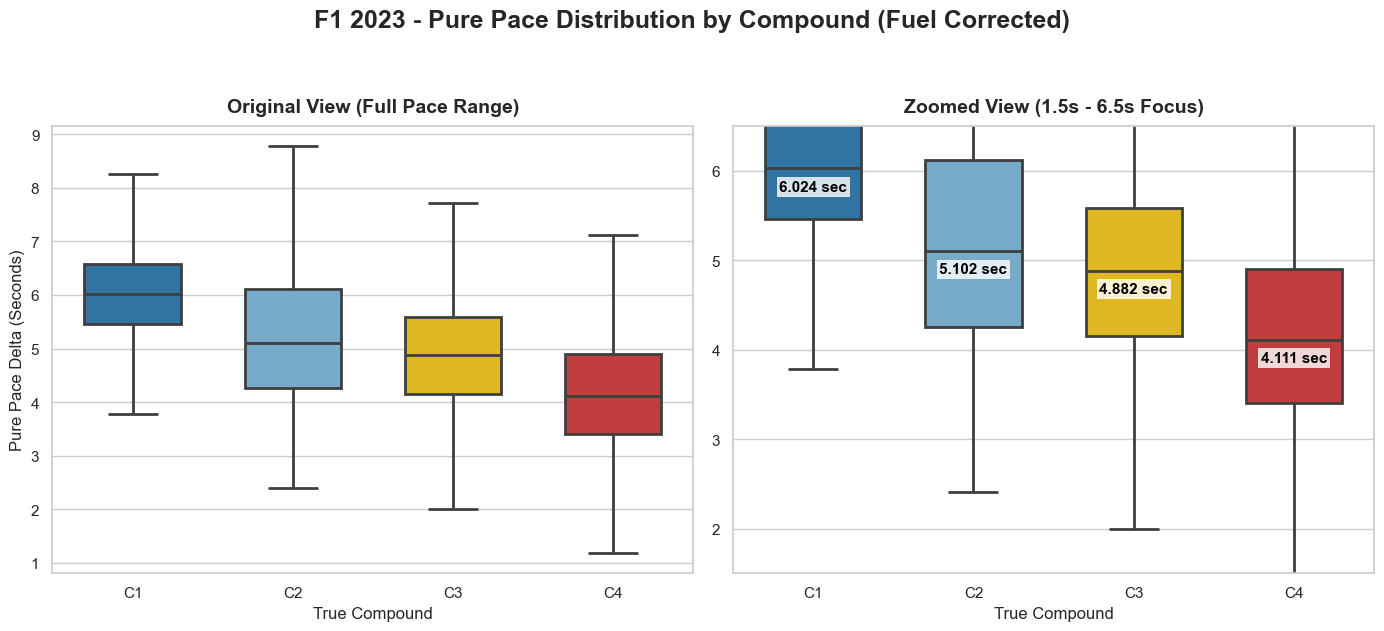

In [ ]:
df = pd.read_csv("f1_2023_8races_clean.csv")

# 徹底剔除排位賽專用的 C5 胎，避免干擾繪圖與期末模型
df = df[df['True_Compound'] != 'C5'].copy()

# ==========================================
# 特徵工程：計算基準秒數與燃油校正
# ==========================================
df['Fastest_Lap'] = df.groupby('RoundNumber')['LapTime_seconds'].transform('min')
df['LapTime_Delta'] = df['LapTime_seconds'] - df['Fastest_Lap']
df['Fuel_Corrected_Delta'] = df['LapTime_Delta'] + (df['LapNumber'] * 0.06)

df_box = df[df['Fuel_Corrected_Delta'] < 10].copy()

# ==========================================
# 繪製 1x2 雙拼圖表 (左：原圖 / 右：放大圖)
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
compound_order = ['C1', 'C2', 'C3', 'C4']
compound_colors = {'C1': '#1f77b4', 'C2': '#6baed6', 'C3': '#ffca00', 'C4': '#d62728'}

# -------------------------
# [左圖] 原圖 (完整 Y 軸範圍)
# -------------------------
sns.boxplot(
    data=df_box, x="True_Compound", y="Fuel_Corrected_Delta",
    hue="True_Compound", hue_order=compound_order, legend=False,  
    order=compound_order, palette=compound_colors,
    showfliers=False, width=0.6, linewidth=2, ax=axes[0]
)
axes[0].set_title("Original View (Full Pace Range)", fontsize=14, fontweight='bold', pad=10)
axes[0].set_xlabel("True Compound", fontsize=12)
axes[0].set_ylabel("Pure Pace Delta (Seconds)", fontsize=12)

# -------------------------
# [右圖] 放大圖 (鎖定 Y 軸 + 中位數標籤)
# -------------------------
sns.boxplot(
    data=df_box, x="True_Compound", y="Fuel_Corrected_Delta",
    hue="True_Compound", hue_order=compound_order, legend=False,  
    order=compound_order, palette=compound_colors,
    showfliers=False, width=0.6, linewidth=2, ax=axes[1]
)
axes[1].set_ylim(1.5, 6.5) 
axes[1].set_title("Zoomed View (1.5s - 6.5s Focus)", fontsize=14, fontweight='bold', pad=10)
axes[1].set_xlabel("True Compound", fontsize=12)
axes[1].set_ylabel("", fontsize=12) 

medians = df_box.groupby(['True_Compound'])['Fuel_Corrected_Delta'].median().round(3)
for i, compound in enumerate(compound_order):
    median_val = medians[compound]
    axes[1].text(
        i, median_val - 0.25, f"{median_val} sec",
        horizontalalignment='center', size=11, color='black', weight='bold',
        bbox=dict(facecolor='white', alpha=0.8, edgecolor='none', pad=2)
    )

fig.suptitle("F1 2023 - Pure Pace Distribution by Compound (Fuel Corrected)", fontsize=18, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()

#### 一樣經過燃油校正後可以看到我們預期的結果 從中位數(剛出場和已跑多圈經過耗損的平均結果)來看，越軟的輪胎確實越有圈速上的優勢，而單圈出現領先0.7~甚至超過1s的表現。放大到至少要跑50圈以上的f1比賽中，使用硬胎跑的時間>使用軟胎*2＋進pit房換胎，那策略組或許就會考慮選擇軟胎並執行換胎的策略。
----------------------------------------------------------

### 圖表三：賽道嚴苛度對輪胎壽命的影響 (Track Severity vs. Tyre Life)

**【圖表目的】**
驗證特徵工程中加入的「賽道嚴苛度指數 (Track_Severity)」是否有效。透過視覺化證明：高側向 G 力與高磨耗的賽道，會實質且顯著地縮短輪胎的最大使用壽命。這將是期末最佳化模型中，針對不同賽道設定「輪胎壽命上限限制式 (Constraints)」的數學依據。

**【實作方法】**
以「車手」與「進站段次 (Stint)」為單位進行群組化 (Groupby)，萃取出每套輪胎的「最大使用圈數 (Max TyreLife)」。接著使用箱型圖觀察不同嚴苛度等級下，輪胎平均壽命的遞減趨勢。為排除爆胎、碰撞退賽或賽事末尾臨時換胎刷最速圈的極端雜訊，我們過濾掉總壽命小於 5 圈的紀錄。

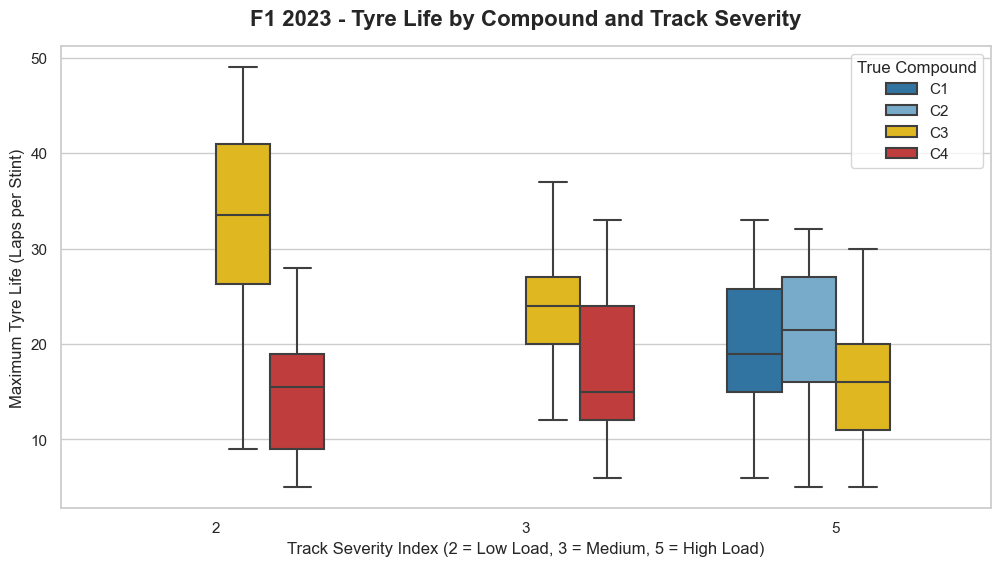

In [9]:
# ==========================================
# 資料轉換：加入 True_Compound 進行分組
# ==========================================
# 這次把 True_Compound 也加入 groupby，確保我們知道每套胎是什麼配方
stint_df = df.groupby(['RoundNumber', 'Driver', 'Stint', 'Track_Severity', 'True_Compound'])['TyreLife'].max().reset_index()

# 排除小於 5 圈的極端雜訊
stint_df_clean = stint_df[stint_df['TyreLife'] >= 5].copy()

# ==========================================
# 繪製群組箱型圖 (Grouped Boxplot)
# ==========================================
plt.figure(figsize=(12, 6))

compound_order = ['C1', 'C2', 'C3', 'C4']
compound_colors = {'C1': '#1f77b4', 'C2': '#6baed6', 'C3': '#ffca00', 'C4': '#d62728'}

# 利用 hue="True_Compound" 讓不同配方在同一個嚴苛度下並排顯示
sns.boxplot(
    data=stint_df_clean,
    x="Track_Severity",
    y="TyreLife",
    hue="True_Compound",
    hue_order=compound_order,
    palette=compound_colors,
    showfliers=False,
    width=0.7,
    linewidth=1.5
)

plt.title("F1 2023 - Tyre Life by Compound and Track Severity", fontsize=16, fontweight='bold', pad=15)
plt.xlabel("Track Severity Index (2 = Low Load, 3 = Medium, 5 = High Load)", fontsize=12)
plt.ylabel("Maximum Tyre Life (Laps per Stint)", fontsize=12)

# 將圖例移到右上角避免擋住資料
plt.legend(title='True Compound', loc='upper right')

plt.show()

### 在嚴苛度2&3的賽道中 只有兩種輪胎表現是因為fia皆在這幾條賽道選擇使用c3 c4 c5作為比賽用胎，但各車隊使用c5胎次數過少，於是我們在前面把c5胎數據給刪除不考慮

### 我們原本可能會預期c1胎在嚴苛度高的情況下表現應比c2胎好，在物理極限下確實如此，但此圖表表現的是策略組的實際策略(啥時叫車手進站換胎)，在單圈速度最慢的情況下，策略組常發生輪胎雖然沒壞，但圈速實在過慢導致提早請車手進站換胎，反而速度跟耐力接兼具的c2胎會更願意讓他留在場上榨乾所有壽命。

### 這就是為何我們不能直接用線性的物理假設(硬度越硬壽命越長)丟進去模型做決策判斷，用真實歷史結果轉換的數據才能做出更符合現實的結果。
----------------


### 圖表四：各賽道進站時間損失分佈 (Pit Loss Distribution by Track)

**【圖表目的】**
量化各賽道的「進站淨時間損失 (Pit Loss)」。在期末建構最佳化模型時，進站換胎是一項帶有「固定設置成本 (Fixed Setup Cost)」的決策。我們必須算出各分站的平均進站耗時，才能將其與「新舊胎單圈速度差」結合，計算出進站換胎的「回本圈數 (Crossover Point)」。

**【實作方法】**
使用原始資料 (Raw Data) 中紀錄的 `PitInTime` 與 `PitOutTime`，計算車輛通過維修區的實際耗時。透過箱型圖觀察 8 條賽道的進站成本差異（例如維修區速限、通道長度不同會導致 Pit Loss 存在顯著差距），並萃取出各站的中位數作為模型的固定參數。

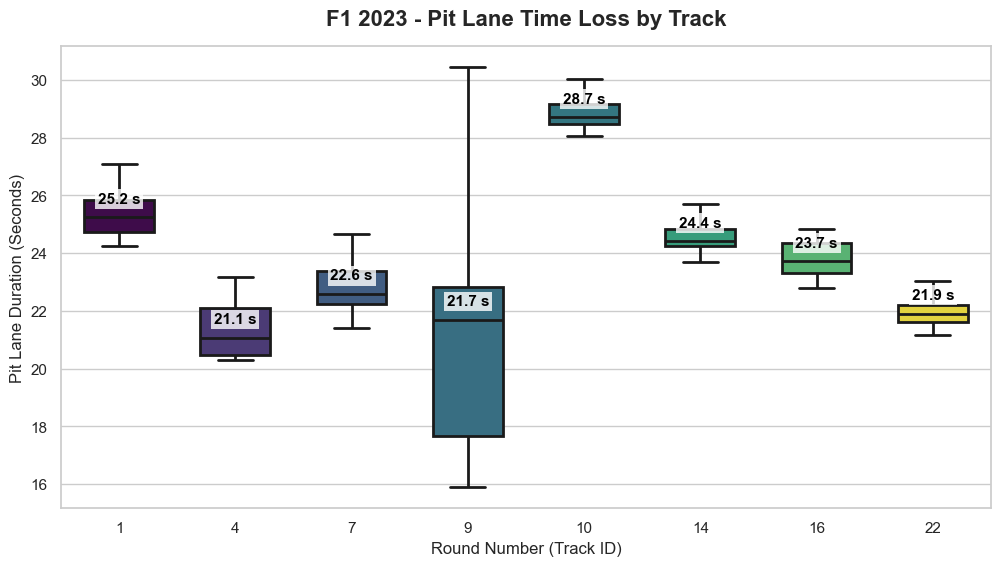

In [10]:
# ==========================================
# 資料準備：從「包含進站紀錄」的資料庫中萃取 Pit Loss
# ==========================================
# 讀取「未經過濾」、保有 PitInTime 與 PitOutTime 的原始資料
df_raw = pd.read_csv("f1_2023_8races_raw.csv")

# 將時間字串轉換為 pandas 的 timedelta 或數值，方便相減
# (FastF1 將這兩個欄位儲存為 timedelta 格式，若已是秒數則無需轉換)
df_raw['PitInTime'] = pd.to_timedelta(df_raw['PitInTime'], errors='coerce')
df_raw['PitOutTime'] = pd.to_timedelta(df_raw['PitOutTime'], errors='coerce')

# 邏輯：在 F1 數據中，PitInTime 紀錄在 In-Lap，PitOutTime 紀錄在 Out-Lap
# 針對同一位車手，把下一圈的 PitOutTime 拉上來跟這一圈的 PitInTime 對齊相減
df_raw['Next_PitOutTime'] = df_raw.groupby('Driver')['PitOutTime'].shift(-1)
df_raw['Pit_Duration_Seconds'] = (df_raw['Next_PitOutTime'] - df_raw['PitInTime']).dt.total_seconds()

# 過濾出合理的進站時間 (排除起跑前、紅旗停頓或異常超過 1 分鐘的雜訊)
# 一般正常進站通過維修區的時間大約在 15 秒到 40 秒之間
df_pit = df_raw[(df_raw['Pit_Duration_Seconds'] >= 15) & (df_raw['Pit_Duration_Seconds'] <= 40)].copy()

# ==========================================
# 繪製各賽道進站時間箱型圖
# ==========================================
plt.figure(figsize=(12, 6))

ax = sns.boxplot(
    data=df_pit,
    x="RoundNumber",
    y="Pit_Duration_Seconds",
    hue="RoundNumber",
    palette="viridis",
    showfliers=False, 
    width=0.6,
    linewidth=2,
    legend=False
)

# 標註各賽道進站時間的中位數
medians_pit = df_pit.groupby('RoundNumber')['Pit_Duration_Seconds'].median()
for i, round_num in enumerate(sorted(df_pit['RoundNumber'].unique())):
    median_val = medians_pit[round_num]
    ax.text(
        i, 
        median_val + 0.5, 
        f"{median_val:.1f} s",
        horizontalalignment='center', 
        size=11, 
        color='black', 
        weight='bold',
        bbox=dict(facecolor='white', alpha=0.8, edgecolor='none', pad=2)
    )

plt.title("F1 2023 - Pit Lane Time Loss by Track", fontsize=16, fontweight='bold', pad=15)
plt.xlabel("Round Number (Track ID)", fontsize=12)
plt.ylabel("Pit Lane Duration (Seconds)", fontsize=12)

plt.show()


-------------

### 圖表五：輪胎性能懸崖捕捉 (Performance Cliff Detection)

**【圖表目的】**
探索輪胎衰退的「非線性特徵」。在期末最佳化模型中，若輪胎衰退呈現完美的線性，模型只需給定固定的斜率參數；但若在特定圈數後出現抓地力崩盤（急遽掉秒），我們就必須透過這張圖抓出「性能拐點 (Inflection Point)」，以此制定強制進站的硬限制 (Hard Constraints) 或 Big-M 懲罰條件。

**【實作方法】**
針對 C2、C3、C4 三款主力配方，繪製輪胎壽命 (TyreLife) 與燃油校正圈速 (Fuel_Corrected_Delta) 的散佈圖。捨棄傳統的線性迴歸，改採 LOESS（局部加權散佈平滑法）擬合趨勢線。觀察各配方曲線尾端斜率陡升的位置，判定該配方的物理極限與性能懸崖落於第幾圈。

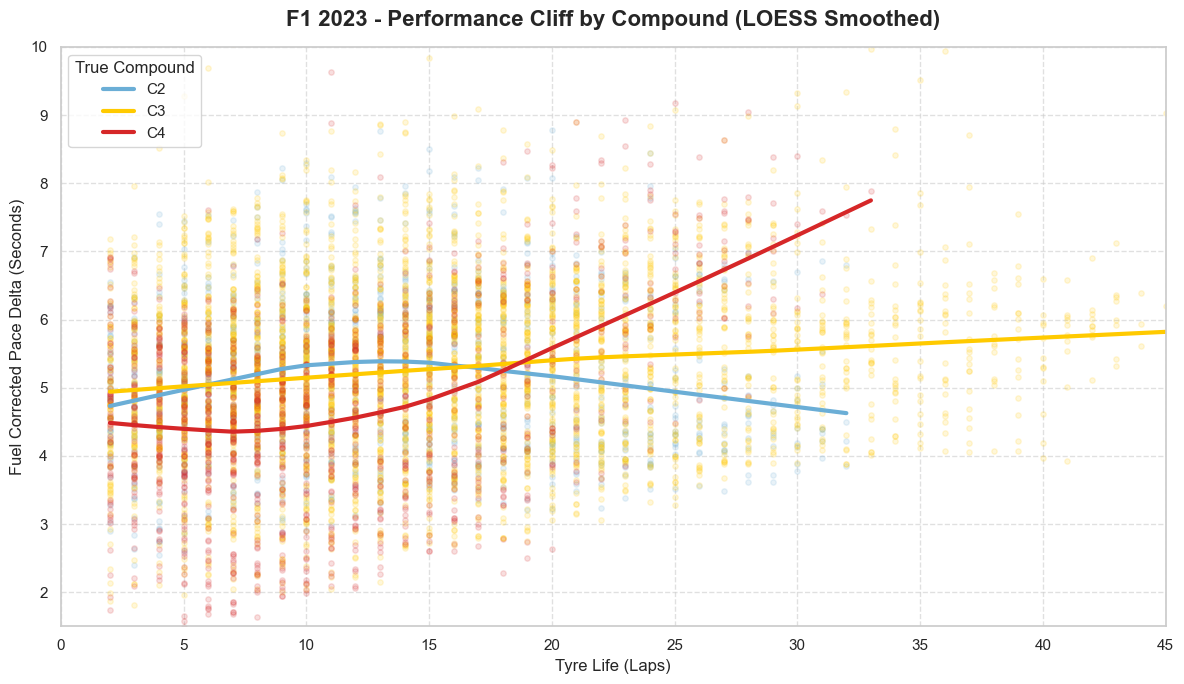

In [11]:
# ==========================================
# 繪製非線性性能懸崖 (LOESS Smoothed Curve)
# ==========================================
plt.figure(figsize=(12, 7))

# 定義配方與對應顏色，排除樣本過少的 C1 與 C5，聚焦主力胎型
target_compounds = ['C2', 'C3', 'C4']
compound_colors = {'C2': '#6baed6', 'C3': '#ffca00', 'C4': '#d62728'}

# 針對每種配方分別繪製帶有 LOESS 平滑的散佈圖
for comp in target_compounds:
    subset = df[df['True_Compound'] == comp]
    
    # lowess=True 會自動呼叫 statsmodels 計算局部平滑曲線
    sns.regplot(
        data=subset, 
        x="TyreLife", 
        y="Fuel_Corrected_Delta",
        scatter_kws={'alpha': 0.15, 's': 15, 'color': compound_colors[comp]}, 
        line_kws={'linewidth': 3, 'label': comp, 'color': compound_colors[comp]}, 
        lowess=True 
    )

# 限制 Y 軸範圍，過濾掉超過 10 秒以上的極端慢圈雜訊，聚焦正常競速範圍
plt.ylim(1.5, 10)
plt.xlim(0, 45)

plt.title("F1 2023 - Performance Cliff by Compound (LOESS Smoothed)", fontsize=16, fontweight='bold', pad=15)
plt.xlabel("Tyre Life (Laps)", fontsize=12)
plt.ylabel("Fuel Corrected Pace Delta (Seconds)", fontsize=12)

plt.legend(title='True Compound', loc='upper left', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

## 搭配圖二＋圖四＋圖五來看 我們可以推測我們還需要幾圈就能追上未進站換胎的車手，實現更好的成績。

##### example:
##### 1. 確立進站的「固定設置成本」 (Fixed Setup Cost)對應圖表：圖表四（各賽道進站時間損失分佈圖）報告說詞：「進站不是免費的。透過我們的箱型圖分析，發現不同賽道的進站成本差異極大。例如第 10 站的進站損失高達 28.7 秒，而第 4 站僅需 21.1 秒。在我們的 Gurobi 模型中，這筆數據將被定義為各賽道的固定進站成本 (Fixed Cost)，模型必須先扣除這個時間，才能計算換胎效益。」
##### 2. 萃取換上新胎的「單圈追回效益」 (Pace Advantage)對應圖表：圖表二（巔峰箱型圖）＋ 圖表五（LOESS 性能懸崖圖）報告說詞：「換上新胎能追回多少時間，是由兩個變數疊加而成的：第一，是配方優勢（來自圖表二），例如全新 C4 本來就比 C2 快大約 1 秒。第二，是擺脫磨損的紅利（來自圖表五），例如原本車上那套舊的 C2 胎已經跑了 20 圈，根據衰退曲線，它已經比全新的狀態慢了 1 秒。兩者相加（1 秒配方優勢 + 1 秒擺脫磨損），我們得出：在這個當下換上全新 C4，每圈可以比繼續用舊 C2 快上整整 2 秒。」
##### 3. 計算出「回本交叉點」 (Crossover Point)報告說詞：「有了成本與單圈效益，我們就能輕易算出數學上的交叉點公式：進站損失時間 ÷ 每圈追回秒數 = 回本所需圈數假設在某條賽道進站損失為 24 秒，而換上新軟胎每圈能追回 2 秒，那麼 $24 \div 2 = 12$。這代表車手必須在場上跑滿 12 圈，這 24 秒的進站代價才會完全回本。」